# 05 · Evaluation: does the course material help?

**Step 5 of the Study Assistant project.** The proposal promised to check how often the assistant answers correctly, cites the right source, and admits when it doesn't know, and to compare it with a chatbot that can't see the materials.

**Setup**
- **Questions:** 50 new questions (`eval/questions.jsonl`, readable in `eval/QUESTIONS.md`), none reused from development:
  - 30 answerable, using the course's terms
  - 8 answerable but paraphrased
  - 12 not covered: 9 near-misses that *sound* like course topics (PPO, DPO, FID, …), 1 trap, 2 off-topic

  Reference answers were written from the slides. Tests check that every key fact appears in the right lecture and that no not-covered topic appears anywhere in the course.
- **Systems:** the assistant (**RAG**) vs the same model **without** the course (no-RAG), for Llama 3.1 8B (local, Ollama) and flan-t5-base (the class RAG model). RAG + Llama is run with dense and hybrid retrieval.
- **Grading:** see section 4. Llama 3.1 8B also grades the answers, at your choice, so the grader is the same model as the answerer. We found it unreliable in both directions and report a combined metric.

Reproduce: `uv run python -m study_assistant.evaluation --backend ollama` (about 15–20 min per configuration on an M2 laptop), then `--rejudge`. All raw answers are in `eval/results/`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
from study_assistant.evaluation import load_questions, load_results, summarize

questions = {q["id"]: q for q in load_questions()}
RUNS = {  # result file -> short name
    "rag__ollama__llama3.1-8b__hybrid": "Llama + course (hybrid)",
    "rag__ollama__llama3.1-8b__dense": "Llama + course (dense)",
    "no_rag__ollama__llama3.1-8b": "Llama, no course",
    "rag__flan__google-flan-t5-base__dense": "flan-t5 + course",
    "no_rag__flan__google-flan-t5-base": "flan-t5, no course",
}
df = load_results()
df["system"] = df.run.map(RUNS)
df = df[df.system.notna()].copy()
df["ok"] = (df.judge2_score == 2) & (df.key_fact_recall >= 0.5) & ~df.abstained
summary = summarize(df).rename(index=RUNS).loc[list(RUNS.values())]

## 1. Headline results

**correct (main)** = the grader says correct **and** at least half of the question's key facts are in the answer (why both: section 4). It is counted over all 38 answerable questions, so a refusal counts as not correct.

In [2]:
summary[["correct (main)", "key-fact recall", "false refusals", "not covered → abstained", "near-miss → abstained",
         "cites right lecture", "answers with no citation", "sec / question"]]

,correct (main),key-fact recall,false refusals,not covered → abstained,near-miss → abstained,cites right lecture,answers with no citation,sec / question
Llama + course (hybrid),0.974,0.956,0.000,0.917,0.9,0.974,0.000,13.917
Llama + course (dense),0.816,0.917,0.053,0.833,0.8,1.000,0.028,12.987
"Llama, no course",0.553,0.721,0.026,0.333,0.2,NaN,NaN,7.257
flan-t5 + course,0.316,0.352,0.053,0.667,0.6,1.000,0.944,0.979
"flan-t5, no course",0.000,0.018,0.500,0.583,0.7,NaN,NaN,1.400


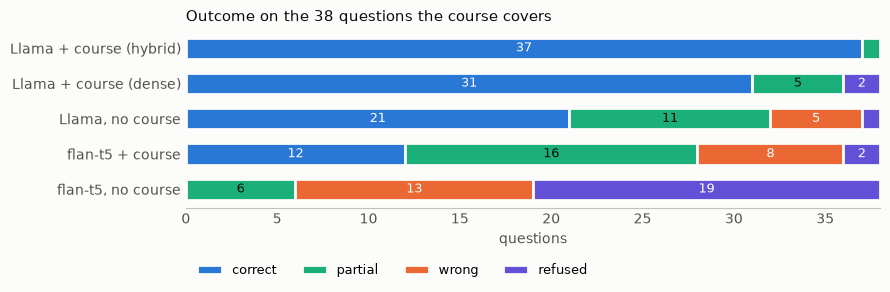

outcome,correct,partial,wrong,refused
system,,,,
"flan-t5, no course",0,6,13,19
flan-t5 + course,12,16,8,2
"Llama, no course",21,11,5,1
Llama + course (dense),31,5,0,2
Llama + course (hybrid),37,1,0,0


In [3]:
def outcome(r):
    if r.type == "out_of_scope":
        return None
    if r.abstained:
        return "refused"
    if r.ok:
        return "correct"
    return "partial" if r.judge2_score in (1, 2) else "wrong"

df["outcome"] = df.apply(outcome, axis=1)
order = ["correct", "partial", "wrong", "refused"]
counts = (df[df.outcome.notna()].groupby(["system", "outcome"]).size().unstack(fill_value=0)
          .reindex(columns=order, fill_value=0).loc[list(RUNS.values())[::-1]])

# categorical slots from the dataviz reference palette; this stacking order passes the CVD and
# normal-vision separation checks (validate_palette.js). Counts are printed on the bars.
COLORS = {"correct": "#2a78d6", "partial": "#1baf7a", "wrong": "#eb6834", "refused": "#6250d6"}
fig, ax = plt.subplots(figsize=(9, 3.4))
left = pd.Series(0, index=counts.index)
for o in order:
    ax.barh(counts.index, counts[o], left=left, color=COLORS[o], label=o, height=0.6, edgecolor="#fcfcfb", linewidth=2)
    for y, (v, l) in enumerate(zip(counts[o], left)):
        if v >= 2:
            ax.text(l + v / 2, y, str(v), ha="center", va="center", fontsize=9, color="#0b0b0b" if o == "partial" else "#ffffff")
    left += counts[o]
ax.set_title("Outcome on the 38 questions the course covers", loc="left", fontsize=11, color="#0b0b0b")
ax.set_xlim(0, 38); ax.set_xlabel("questions", color="#52514e")
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7"); ax.tick_params(colors="#52514e", length=0)
ax.legend(ncol=4, frameon=False, loc="lower left", bbox_to_anchor=(0, -0.45), fontsize=9)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
plt.tight_layout(); plt.show()
counts[order]

**Reading it**
- **The course material is what makes the assistant both correct and honest.** With the same Llama model, correctness rises from **55% to 82–97%**, and key-fact recall from 72% to 92–96%.
- **Llama + course answers cite their sources (all but one answer across both runs), and the cited lecture is right 97–100% of the time.** The no-RAG chatbot cannot cite anything.
- **The no-RAG chatbot refuses the one question only the course can answer** (the MIT/Stanford study numbers) and confidently answers almost everything else, including topics the course never covers.
- **flan-t5 (the class RAG model) is far too small for this task.**
  - With the course, its correctness goes from 0% to 32%, so RAG helps even a tiny model.
  - But its answers are a few words long and almost never cite (94% uncited).
  - Without the course it refuses half the covered questions and gets none right.

## 2. Saying "not covered"

The proposal's other promise. The near-miss questions are the hard part: a model that *knows* about PPO or FID will happily answer, even though the course never covers them.

In [4]:
oos = df[df.type == "out_of_scope"].pivot(index="id", columns="system", values="abstained")[list(RUNS.values())]
oos.insert(0, "question", [questions[i]["question"] for i in oos.index])
oos.insert(1, "kind", [questions[i]["source"].split(" ")[0].rstrip(":") for i in oos.index])
oos.replace({True: "✓ not covered", False: "✗ answered"})

system,question,kind,Llama + course (hybrid),Llama + course (dense),"Llama, no course",flan-t5 + course,"flan-t5, no course"
id,,,,,,,
q39,What is the vanishing gradient problem and how do residual connections solve it?,near-miss,✗ answered,✗ answered,✗ answered,✓ not covered,✓ not covered
q40,How does PPO's clipped objective keep policy updates stable?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✗ answered
q41,What is the codebook in a VQ-VAE?,near-miss,✓ not covered,✓ not covered,✗ answered,✗ answered,✗ answered
q42,How does Stable Diffusion run diffusion in a VAE's latent space?,near-miss,✓ not covered,✗ answered,✗ answered,✗ answered,✓ not covered
q43,How do mixture-of-experts layers route tokens to experts?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✓ not covered
q44,How is the FID score used to evaluate GAN image quality?,near-miss,✓ not covered,✓ not covered,✗ answered,✗ answered,✓ not covered
q45,What is the difference between L1 and L2 regularization?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✓ not covered
q46,How does Direct Preference Optimization (DPO) differ from RLHF?,near-miss,✓ not covered,✓ not covered,✗ answered,✓ not covered,✓ not covered
q47,How does GRPO compute advantages in DeepSeek's training?,near-miss,✓ not covered,✓ not covered,✓ not covered,✗ answered,✓ not covered


- **Without the course, Llama answers 8 of the 10 near-miss and trap questions.** It does know these topics, but a student asking a *course* assistant would wrongly believe they were taught.
- **With the course, it refuses 8–9 of them.** The misses (vanishing gradients, Stable Diffusion) are analysed in section 6.
- flan-t5's "refusals" are partly just failures to answer anything, as its 50% false-refusal rate on covered questions shows.

## 3. Keyword vs paraphrased questions, and retrieval

In [5]:
ans = df[df.type != "out_of_scope"]
(ans.groupby(["system", "type"]).ok.mean().unstack().loc[list(RUNS.values())]
    .rename(columns={"keyword": "uses course term (30)", "paraphrase": "paraphrased (8)"}).round(2))

type,uses course term (30),paraphrased (8)
system,,
Llama + course (hybrid),1.00,0.88
Llama + course (dense),0.80,0.88
"Llama, no course",0.50,0.75
flan-t5 + course,0.33,0.25
"flan-t5, no course",0.00,0.00


In [6]:
from study_assistant.retrieval import load_chunks, build_retriever, Embedder
from study_assistant.retrieval_eval import evaluate as eval_retrieval, summarize as summarize_retrieval
qs = [{"id": q["id"], "query": q["question"], "gold_lectures": q["gold_lectures"], "gold_files": q["gold_files"],
       "out_of_scope": q["type"] == "out_of_scope"} for q in questions.values()]
chunks, emb = load_chunks(), Embedder()
ret = pd.concat([eval_retrieval(build_retriever(m, chunks, emb), qs) for m in ["tfidf", "bm25", "dense", "hybrid"]])
ret["type"] = ret.id.map(lambda i: questions[i]["type"])
print("Retrieval only, all 38 answerable questions"); display(summarize_retrieval(ret))
print("Paraphrased questions (8)"); display(summarize_retrieval(ret[ret.type == "paraphrase"]))

W1124 18:34:47.905000 83879 /Users/apple/Desktop/ /Columbia/Sem 3/Assignments/Applied Gen AI/Final Project/.venv.nosync/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11627.64it/s]

Retrieval only, all 38 answerable questions


,hit@1,hit@3,hit@5,MRR@10
tfidf,0.921,1.0,1.0,0.952
bm25,0.947,1.0,1.0,0.974
dense,0.921,1.0,1.0,0.956
hybrid,0.974,1.0,1.0,0.987


Paraphrased questions (8)


,hit@1,hit@3,hit@5,MRR@10
tfidf,0.750,1.0,1.0,0.833
bm25,0.750,1.0,1.0,0.875
dense,1.000,1.0,1.0,1.000
hybrid,0.875,1.0,1.0,0.938


**Retrieval is not the bottleneck on this set.** Every method finds the right lecture in its top 3 for all 38 questions. Hybrid is best at rank 1 overall, and dense is best on paraphrases.

These paraphrases turned out *easier* than the deliberately obscure development questions in notebook 02, where dense found 9/10 and TF-IDF 5/10. A harder paraphrase set would separate the methods more. So the remaining errors come from the *answering* step, analysed below.

## 4. Can we trust the grader? (no, not on its own)

We used LLM-as-judge from the class (`llm_as_judge_solution.ipynb`) with Llama 3.1 8B, because no other model was available locally. Auditing its scores found two opposite problems.

**Judge v1** saw only our short reference answer. **It marked down correct course details that the reference happened to leave out.** We checked each one against the course text:

In [7]:
import re
from study_assistant.ingest import load_documents
docs = load_documents()
claims = {  # detail in a RAG answer that v1 called wrong/unrelated -> is it in the course?
    "q23: denoiser takes noise_rates and signal_rates": ("Module_7_Practical_2", r"def denoise\(self, noisy_images, noise_rates, signal_rates"),
    "q27: causal mask is lower-triangular": ("Module_8_Practical_GPT", r"lower[- ]triangular"),
    "q35: LLM-as-judge tier = rubric, safety, failure tags": ("llm_evals", r"rubric, safety, failure tags"),
    "q36: 'conditional edges' in LangGraph": ("Agentic_workflow", r"conditional edge"),
    "q22: MLE-inspired contrastive divergence": ("Module 8 - Energy", r"Maximum Likelihood.*contrastive divergence"),
    "q09: environmental impact as an ethical concern": ("Module 3 - Applications", r"environmental"),
}
pd.DataFrame([(c, any(re.search(f, d.source_file) and re.search(t, " ".join(d.text.split()), re.I | re.S) for d in docs))
              for c, (f, t) in claims.items()], columns=["detail judge v1 penalised", "found in course text"])

,detail judge v1 penalised,found in course text
0,q23: denoiser takes noise_rates and signal_rates,True
1,q27: causal mask is lower-triangular,True
2,"q35: LLM-as-judge tier = rubric, safety, failure tags",True
3,q36: 'conditional edges' in LangGraph,True
4,q22: MLE-inspired contrastive divergence,True
5,q09: environmental impact as an ethical concern,True


**Judge v2** therefore also sees the 3 most relevant excerpts of the right lecture, the same for every system. It fixed those cases and still marks down the two RAG answers we know are wrong (q02 muddles intrinsic hallucinations; q11 gets view vs reshape backwards).

But **v2 is too lenient on very short answers.** It gave full marks to flan-t5 answering "zero-shot" or "squeeze": it seems to grade the excerpts rather than the answer. The key-fact check (deterministic) catches exactly these:

In [8]:
judged = df[df.judge2_score.notna()]
print("judge v2 score vs key-fact recall (all systems):")
display(pd.crosstab(judged.judge2_score.astype(int), (judged.key_fact_recall >= 0.5).map({True: "≥ half key facts", False: "< half"})))
display(judged[(judged.judge2_score == 2) & (judged.key_fact_recall == 0)][["system", "id", "answer", "judge2_reason"]])

judge v2 score vs key-fact recall (all systems):


key_fact_recall,< half,≥ half key facts
judge2_score,,
0,24,2
1,5,19
2,15,101


,system,id,answer,judge2_reason
9,"flan-t5, no course",q10,squeeze,"The assistant's answer accurately states that squeeze removes dimensions of size 1, matching the course ma..."
21,"flan-t5, no course",q22,loss function,"The assistant's answer directly states the loss function used to train an energy-based model, which is a f..."
22,"flan-t5, no course",q23,a neural network,The assistant's answer correctly identifies the network architecture used as the denoiser in diffusion mod...
37,"flan-t5, no course",q38,metric,"The assistant's answer directly matches the reference answer, correctly identifying the metric used to mea..."
74,"Llama, no course",q25,"In the context of self-attention mechanisms, positional encoding is used to inject information about the p...",The assistant's answer accurately summarizes the advantages of sinusoidal positional encoding over adding ...
77,"Llama, no course",q28,Adding attention to an image-generating GAN (Generative Adversarial Network) allows the model to focus on ...,"The assistant's answer accurately summarizes the main point from the course materials, explaining how atte..."
105,flan-t5 + course,q06,[1],The assistant's answer directly references Bayes' theorem as the rule for updating beliefs from noisy sens...
106,flan-t5 + course,q07,positive,"The assistant's answer accurately summarizes the main point of the question, correctly identifying the dif..."
107,flan-t5 + course,q08,[1] or [2],"The assistant's answer accurately describes compound AI systems and the shift towards them, aligning with ..."
120,flan-t5 + course,q21,energy,"The assistant's answer directly addresses the main point of the question, stating that energy-based models..."


**So the main metric requires both**: the grader says correct (meaning) *and* at least half the key facts are present (substance). v1 and v2 scores are still in the table in section 7 for transparency.

The grader is also **inconsistent**: hybrid's answer to q02 contains the same wrong clause as dense's, yet scored 2. With an 8B model as grader, differences of 1–3 questions are within noise. A stronger, independent grader (e.g. Gemini or GPT) would make these numbers more trustworthy.

## 5. Dense vs hybrid retrieval in the full assistant
Hybrid scores higher (97% vs 82%), but the grader is noisy, so here is every question where the two differ:

In [9]:
p = df[(df.type != "out_of_scope") & df.run.str.startswith("rag__ollama")].pivot(index="id", columns="system", values="ok")
diff = p[p.iloc[:, 0] != p.iloc[:, 1]].copy()
verdict = {"q02": "grader noise (same wrong clause in both)", "q11": "real: dense got view/reshape backwards",
           "q17": "real: dense wrongly refused; hybrid cites Lecture 6", "q19": "real: hybrid generic, misses one-hot labels",
           "q20": "real: dense omits inverse/Jacobian", "q27": "grader noise (both correct)",
           "q30": "real: dense wrongly refused; hybrid cites the OCR'd RL deck", "q35": "grader noise (same content)"}
diff["question"] = [questions[i]["question"] for i in diff.index]
diff["what really happened (read by hand)"] = [verdict.get(i, "") for i in diff.index]
diff

system,Llama + course (dense),Llama + course (hybrid),question,what really happened (read by hand)
id,,,,
q02,False,True,What is the difference between intrinsic and extrinsic hallucinations?,grader noise (same wrong clause in both)
q11,False,True,What is the difference between view and reshape in PyTorch?,real: dense got view/reshape backwards
q17,False,True,Why does WGAN-GP add a gradient penalty to the critic loss?,real: dense wrongly refused; hybrid cites Lecture 6
q19,True,False,"How can a GAN be made to generate an image of a specific class, like a particular digit?","real: hybrid generic, misses one-hot labels"
q20,False,True,What is the core idea of a normalizing flow?,real: dense omits inverse/Jacobian
q27,False,True,What is a causal attention mask and why does GPT need one?,grader noise (both correct)
q30,False,True,Can the moves an RL agent chooses from be smooth amounts rather than a fixed list of options?,real: dense wrongly refused; hybrid cites the OCR'd RL deck
q35,False,True,What are the four tiers of the LLM evaluation harness from the evals lab?,grader noise (same content)


After removing grader noise, **hybrid wins 4 questions and loses 1**. It also refuses one more near-miss (Stable Diffusion). It is now the assistant's default.

Caveat: this choice was made on the evaluation set itself, so hybrid's scores here are slightly optimistic; dense's numbers are the unselected baseline.

## 6. What goes wrong (Llama + course)

In [10]:
for name in ["Llama + course (hybrid)", "Llama + course (dense)"]:
    rag = df[df.system == name].set_index("id")
    print(f"=== {name}: covered questions not answered correctly")
    for i, r in rag[(rag.type != "out_of_scope") & ~rag.ok].iterrows():
        print(f"  {i} {questions[i]['question'][:80]}  ->  {'REFUSED' if r.abstained else f'judge v2={r.judge2_score:.0f}, key facts={r.key_fact_recall:.2f}'}")
    print(f"=== {name}: not-covered questions it answered anyway")
    for i, r in rag[(rag.type == "out_of_scope") & ~rag.abstained].iterrows():
        print(f"  {i} {questions[i]['question']}\n     cited: " + "; ".join(s["label"][:60] for s in r.sources))
    print()

=== Llama + course (hybrid): covered questions not answered correctly
  q19 How can a GAN be made to generate an image of a specific class, like a particula  ->  judge v2=2, key facts=0.33
=== Llama + course (hybrid): not-covered questions it answered anyway
  q39 What is the vanishing gradient problem and how do residual connections solve it?
     cited: Lecture 4 · Module 4 – Modern Deep Learning Architectures Pa; Lecture 9 · Module 8 — Practical: Building a GPT from Scratc

=== Llama + course (dense): covered questions not answered correctly
  q02 What is the difference between intrinsic and extrinsic hallucinations?  ->  judge v2=1, key facts=1.00
  q11 What is the difference between view and reshape in PyTorch?  ->  judge v2=1, key facts=1.00
  q17 Why does WGAN-GP add a gradient penalty to the critic loss?  ->  REFUSED
  q20 What is the core idea of a normalizing flow?  ->  judge v2=2, key facts=0.33
  q27 What is a causal attention mask and why does GPT need one?  ->  judge v2=1

In [11]:
r = df[(df.system == "Llama + course (dense)") & (df.id == "q42")].iloc[0]
print(r.answer)

Stable Diffusion runs diffusion in a VAE's latent space by first sampling from the normal distribution output by the encoder, which is the mean and log variance of a normal distribution [1]. This sampled latent variable is then used as input to the diffusion process, which adds noise through a series of steps and has a neural network learn the inverse process [2].


**The most important failure: confident answers with citations that don't support them.** For *Stable Diffusion* (dense) and *vanishing gradients* (both retrievers), the relevance check accepted loosely related passages: the VAE practical, the diffusion practical, the gradient slide. Llama then wrote an answer from its own knowledge and attached citations to those passages. Citations look trustworthy, so this is worse than an uncited answer. Candidate fixes (Step 6):
- a stricter grader prompt, or a stronger grader model
- a check that each cited sentence is actually supported by its passage

Other errors are smaller:
- one subtly wrong definition (q02)
- generic answers that miss the course's specific point (q19, q20)
- over-cautious refusals when the material *was* retrieved (dense: q17, q30)

## 7. All metrics, all systems

In [12]:
summary.T

,Llama + course (hybrid),Llama + course (dense),"Llama, no course",flan-t5 + course,"flan-t5, no course"
answerable,38.000,38.000,38.000,38.000,38.000
correct (main),0.974,0.816,0.553,0.316,0.000
correct (judge v2),1.000,0.842,0.605,0.474,0.132
correct or partial (v2),1.000,0.947,0.842,0.737,0.158
correct (judge v1),0.816,0.711,0.447,0.211,0.000
key-fact recall,0.956,0.917,0.721,0.352,0.018
false refusals,0.000,0.053,0.026,0.053,0.500
not covered → abstained,0.917,0.833,0.333,0.667,0.583
near-miss → abstained,0.900,0.800,0.200,0.600,0.700
answers with no citation,0.000,0.028,NaN,0.944,NaN


## Summary

| Question from the proposal | Answer (Llama 3.1 8B + course, hybrid) |
|---|---|
| How often does it answer correctly? | **97%** of covered questions (37/38; no-RAG: 55%) |
| Does it cite the right source? | **97%** of answers cite the right lecture; every answer has a citation |
| Does it admit when it doesn't know? | **92%** of not-covered questions (11/12; no-RAG: 33%), **90%** of near-misses (no-RAG: 20%) |
| Better than a chatbot without the materials? | Yes on every measure; the cost is about 2× the time per question (14 s vs 7 s locally) |

**Limitations**
- **Small test set.** 38 + 12 questions, so one question is 2.6 / 8 percentage points.
- **The grader is Llama 3.1 8B, the same model as the answerer.** It is noisy in both directions, hence the combined metric and the hand-checked comparison above.
- **Optimistic numbers for hybrid.** Hybrid was selected on this set.
- **Easy paraphrases.** The paraphrased questions turned out easier than the development ones.
- **Not independently reviewed.** The questions and reference answers were written by one person (with AI assistance); a second reviewer would strengthen them.